# What Brews a Winning Cup?
*Bryan Larison • Gina Fuller • Alexandra Hagen • Garrett Williford*

An analysis of 1,338 professional coffee reviews from the Coffee Quality Institute (CQI): which sensory traits set
the best coffees apart, and how much of a coffee's score can be predicted from where and how it was grown.

**What changed from the original class submission** (in `archive/v1/`)
- One cleaning section used by every analysis (v1 repeated cleaning per chart).
- Fixed data errors: a 0-point review, altitude typos (up to 190,164 m), unparsed grading dates, and moisture recorded as 0.
- Added significance tests so small differences aren't over-read.
- Added predictive models (linear regression and Random Forest) to weigh which farm-level factors actually matter.

## 1. Questions
1. Which sensory attributes separate the top 10% of coffees from the rest?
2. Have scores become more consistent over time?
3. Does processing method affect flavor?
4. How does growing altitude relate to quality?
5. Which countries produce the highest-scoring coffee?
6. **How well can we predict a coffee's score from farm and processing data alone, and which factors carry the most weight?**

## 2. Setup
`pandas`/`numpy` for wrangling, `scipy`/`statsmodels` for tests and regression, `scikit-learn` for the predictive models,
`matplotlib`/`seaborn` for charts.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ESPRESSO, CARAMEL, CREMA, LEAF, GREY = "#3B2418", "#C8873A", "#E9D3B4", "#5B8C5A", "#8A8178"
sns.set_theme(style="whitegrid", font="Arial")
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 13, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 200,
                     "savefig.bbox": "tight"})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
results = {}  # key numbers, saved at the end for the slides and README

## 3. Data preparation
Source: CQI reviews scraped in January 2018 by James Ledoux, published via
[TidyTuesday](https://github.com/rfordatascience/tidytuesday/blob/main/data/2020/2020-07-07/readme.md).
1,339 reviews (1,311 arabica, 28 robusta), 43 columns.

`total_cup_points` is the official CQI score. It is exactly the sum of 10 sensory scores (aroma, flavor, aftertaste,
acidity, body, balance, uniformity, clean cup, sweetness, cupper points), which matters for Section 9.

All cleaning happens in one function so every chart and model uses the same data.

In [2]:
SENSORY = ["aroma", "flavor", "aftertaste", "acidity", "body", "balance",
           "uniformity", "clean_cup", "sweetness", "cupper_points"]

raw = pd.read_csv("coffee_ratings.csv")
gap = (raw[SENSORY].sum(axis=1) - raw["total_cup_points"]).abs().max()
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
print(f"Largest gap between the sum of the 10 sensory scores and total_cup_points: {gap:.2f} points")

Rows: 1,339   Columns: 43
Largest gap between the sum of the 10 sensory scores and total_cup_points: 0.50 points


In [3]:
def clean(raw: pd.DataFrame) -> tuple[pd.DataFrame, list]:
    df, log = raw.copy(), []

    # One review has every score at 0, a data-entry error
    bad = df["total_cup_points"] <= 0
    log.append(("Removed review with a total score of 0", int(bad.sum())))
    df = df[~bad].copy()

    # Grading date: "April 4th, 2015" -> 2015 (v1's string split misread 2 rows)
    dates = df["grading_date"].str.replace(r"(\d+)(st|nd|rd|th)", r"\1", regex=True)
    df["grading_year"] = pd.to_datetime(dates, format="%B %d, %Y", errors="coerce").dt.year.astype("Int64")

    # Altitude: altitude_mean_meters is already unit-converted, but contains typos (e.g. 190,164 m).
    # Coffee is grown between roughly 100 m and 3,000 m, so values outside that range become missing.
    ok = df["altitude_mean_meters"].between(100, 3000)
    log.append(("Altitude outside 100–3,000 m set to missing",
                int((df["altitude_mean_meters"].notna() & ~ok).sum())))
    df["altitude_m"] = df["altitude_mean_meters"].where(ok)
    df["alt_band"] = pd.cut(df["altitude_m"], [0, 1000, 1300, 1600, 3000],
                            labels=["<1000 m", "1000–1299 m", "1300–1599 m", "≥1600 m"])

    # Moisture of 0% is physically impossible for green coffee: treat as not recorded
    log.append(("Moisture of 0 set to missing", int((df["moisture"] == 0).sum())))
    df["moisture"] = df["moisture"].replace(0, np.nan)

    # Group rare categories so models and charts aren't driven by 1–2 samples
    def group(col, min_n=20, missing="Unknown"):
        counts = df[col].value_counts()
        return df[col].where(df[col].isin(counts[counts >= min_n].index), "Other").where(df[col].notna(), missing)

    df["country"] = group("country_of_origin").replace({"Tanzania, United Republic Of": "Tanzania"})
    df["variety_g"] = group("variety")
    df["processing"] = df["processing_method"].fillna("Unknown")
    df["color_g"] = df["color"].fillna("Unknown")
    return df, log

df, log = clean(raw)
display(pd.DataFrame(log, columns=["Cleaning step", "Rows affected"]))
print(f"Clean dataset: {len(df):,} reviews")
results["n_reviews"] = len(df)

,Cleaning step,Rows affected
0,Removed review with a total score of 0,1
1,"Altitude outside 100–3,000 m set to missing",35
2,Moisture of 0 set to missing,264


Clean dataset: 1,338 reviews


## 4. Q1: Which sensory attributes separate the best coffees?
We define "top coffees" as the top 10% by total cup points, then compare each attribute between the top group and the rest.

*v1 compared attributes within the top 10% only. Restricting the range that way weakens correlations, so here the
comparison uses all coffees.*

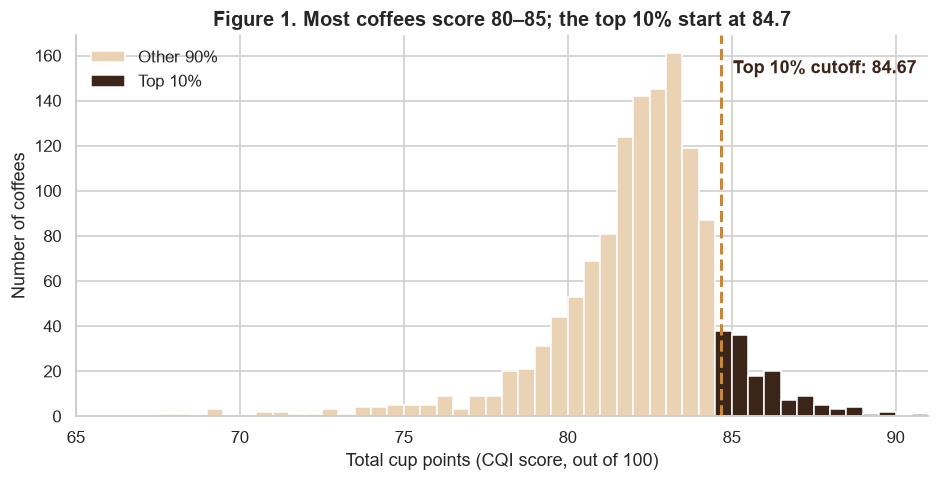

count    1338.00
mean       82.15
std         2.69
min        59.83
25%        81.10
50%        82.50
75%        83.67
max        90.58
Name: total_cup_points, dtype: float64


In [4]:
cutoff = df["total_cup_points"].quantile(0.90)
df["top10"] = df["total_cup_points"] >= cutoff
results["top10_cutoff"] = round(cutoff, 2)

fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.arange(59, 91.5, 0.5)
ax.hist(df.loc[~df["top10"], "total_cup_points"], bins=bins, color=CREMA, edgecolor="white", label="Other 90%")
ax.hist(df.loc[df["top10"], "total_cup_points"], bins=bins, color=ESPRESSO, edgecolor="white", label="Top 10%")
ax.axvline(cutoff, color=CARAMEL, ls="--", lw=2)
ax.annotate(f"Top 10% cutoff: {cutoff:.2f}", (cutoff, ax.get_ylim()[1] * 0.9), xytext=(8, 0),
            textcoords="offset points", color=ESPRESSO, fontweight="bold")
ax.set(title="Figure 1. Most coffees score 80–85; the top 10% start at {:.1f}".format(cutoff),
       xlabel="Total cup points (CQI score, out of 100)", ylabel="Number of coffees", xlim=(65, 91))
ax.legend(frameon=False)
fig.savefig(FIG / "fig1_score_distribution.png"); plt.show()
print(df["total_cup_points"].describe().round(2))

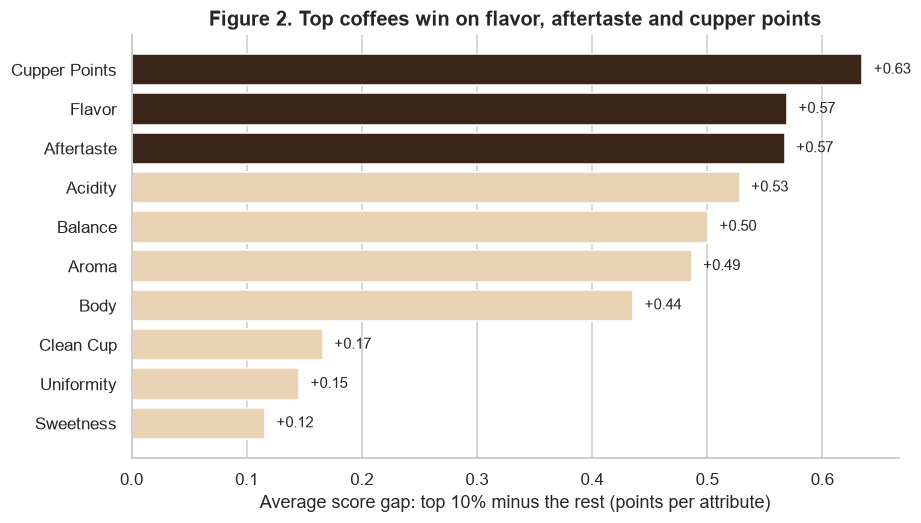

,top10_mean,rest_mean,gap_points,corr_with_total
cupper_points,8.075,7.441,0.635,0.741
flavor,8.034,7.465,0.569,0.827
aftertaste,7.913,7.346,0.567,0.812
acidity,8.013,7.484,0.528,0.697
balance,7.970,7.470,0.501,0.763
aroma,8.007,7.520,0.487,0.686
body,7.912,7.476,0.436,0.628
clean_cup,9.991,9.825,0.166,0.603
uniformity,9.972,9.827,0.146,0.515
sweetness,9.967,9.852,0.116,0.396


In [5]:
top, rest = df[df["top10"]], df[~df["top10"]]
attr = pd.DataFrame({
    "top10_mean": top[SENSORY].mean(),
    "rest_mean": rest[SENSORY].mean(),
    "gap_points": top[SENSORY].mean() - rest[SENSORY].mean(),
    "corr_with_total": df[SENSORY].corrwith(df["total_cup_points"]),
}).sort_values("gap_points")

fig, ax = plt.subplots(figsize=(9, 5))
colors = [ESPRESSO if a in attr.index[-3:] else CREMA for a in attr.index]
ax.barh(attr.index.str.replace("_", " ").str.title(), attr["gap_points"], color=colors)
for i, v in enumerate(attr["gap_points"]):
    ax.text(v + 0.01, i, f"+{v:.2f}", va="center", fontsize=10)
ax.set(title="Figure 2. Top coffees win on flavor, aftertaste and cupper points",
       xlabel="Average score gap: top 10% minus the rest (points per attribute)")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "fig2_attribute_gap.png"); plt.show()
display(attr.sort_values("gap_points", ascending=False).round(3))
results["attribute_gap"] = attr["gap_points"].sort_values(ascending=False).round(3).to_dict()

**Finding.** The top 10% beat the rest on every attribute, but the gap is largest for flavor, aftertaste and the
cupper's overall impression. Uniformity, clean cup and sweetness barely differ: nearly every coffee scores close
to a perfect 10 on them, so they rarely decide who wins.

## 5. Q2: Have scores become more consistent over time?
v1 used `harvest_year`, which is messy free text (e.g. "Abril - Julio"). Grading year is recorded for every review, so we use it instead.

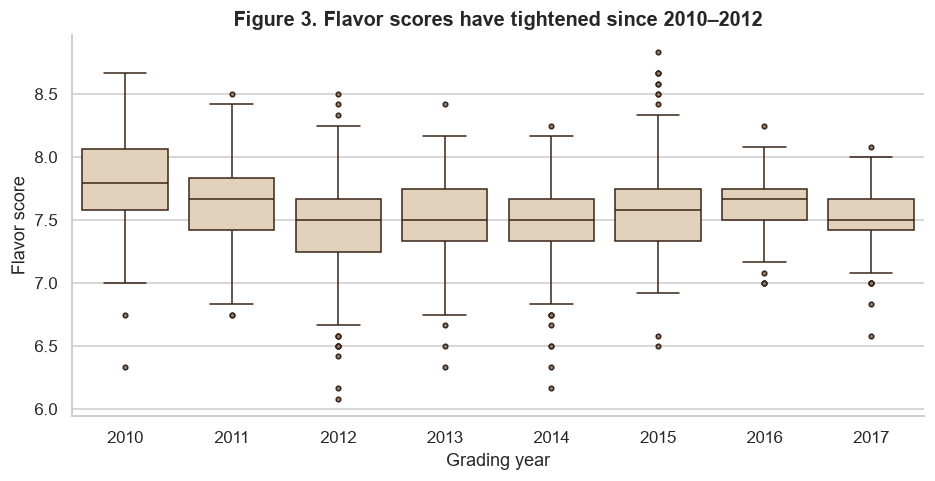

Flavor std 2010–12: 0.392 (n=449)   2015–17: 0.294 (n=465)
Levene test for equal variance: W=25.5, p=5.4e-07


,count,mean,std
grading_year,,,
2010,50,7.767,0.446
2011,83,7.624,0.334
2012,316,7.437,0.373
2013,154,7.507,0.318
2014,262,7.476,0.333
2015,197,7.591,0.356
2016,127,7.618,0.221
2017,141,7.522,0.247


In [6]:
yearly = df[df["grading_year"].between(2010, 2017)]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=yearly, x="grading_year", y="flavor", color=CREMA, linecolor=ESPRESSO,
            flierprops={"marker": "o", "markersize": 3, "markerfacecolor": GREY}, ax=ax)
ax.set(title="Figure 3. Flavor scores have tightened since 2010–2012",
       xlabel="Grading year", ylabel="Flavor score")
fig.savefig(FIG / "fig3_flavor_by_year.png"); plt.show()

early = df.loc[df["grading_year"] <= 2012, "flavor"]
late = df.loc[df["grading_year"].between(2015, 2017), "flavor"]
lev = stats.levene(early, late)
print(f"Flavor std 2010–12: {early.std():.3f} (n={len(early)})   2015–17: {late.std():.3f} (n={len(late)})")
print(f"Levene test for equal variance: W={lev.statistic:.1f}, p={lev.pvalue:.1e}")
display(yearly.groupby("grading_year")["flavor"].agg(["count", "mean", "std"]).round(3))
results["consistency"] = {"std_early": round(early.std(), 3), "std_late": round(late.std(), 3), "p": float(lev.pvalue)}

**Finding.** The spread of flavor scores dropped by about a quarter between 2010–2012 and 2015–2017, and a
Levene test confirms the difference is statistically significant. Because 2010–2011 have fewer reviews, part of
this could reflect *which* coffees were submitted rather than better farming.

## 6. Q3: Does processing method affect flavor?
170 reviews have no processing method and are left out here. We add 95% confidence intervals and a Kruskal-Wallis
test (which does not assume normal data) to check whether the differences are real.

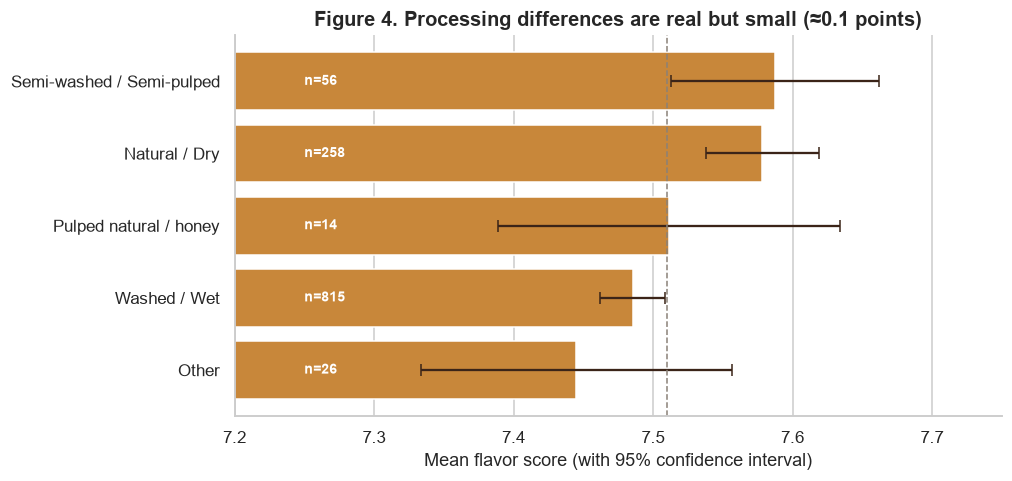

Kruskal-Wallis H=16.4, p=0.0025, effect size ε²=0.011
Natural vs Washed: Mann-Whitney p=0.0004


,mean,sem,n,ci95
processing_method,,,,
Semi-washed / Semi-pulped,7.587,0.038,56,0.075
Natural / Dry,7.578,0.021,258,0.040
Pulped natural / honey,7.511,0.063,14,0.123
Washed / Wet,7.486,0.012,815,0.023
Other,7.445,0.057,26,0.112


In [7]:
proc = df.dropna(subset=["processing_method"])
ps = (proc.groupby("processing_method")["flavor"]
          .agg(mean="mean", sem="sem", n="count").sort_values("mean"))
ps["ci95"] = 1.96 * ps["sem"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(ps.index, ps["mean"], xerr=ps["ci95"], color=CARAMEL, ecolor=ESPRESSO, capsize=4)
for i, (m, n) in enumerate(zip(ps["mean"], ps["n"])):
    ax.text(7.25, i, f"n={n}", va="center", ha="left", color="white", fontsize=9, fontweight="bold")
ax.axvline(proc["flavor"].mean(), color=GREY, ls="--", lw=1)
ax.set(xlim=(7.2, 7.75), xlabel="Mean flavor score (with 95% confidence interval)",
       title="Figure 4. Processing differences are real but small (≈0.1 points)")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "fig4_processing.png"); plt.show()

groups = [g["flavor"].values for _, g in proc.groupby("processing_method")]
kw = stats.kruskal(*groups)
eps2 = (kw.statistic - len(groups) + 1) / (len(proc) - len(groups))
print(f"Kruskal-Wallis H={kw.statistic:.1f}, p={kw.pvalue:.4f}, effect size ε²={eps2:.3f}")
mw = stats.mannwhitneyu(proc.loc[proc["processing_method"] == "Natural / Dry", "flavor"],
                        proc.loc[proc["processing_method"] == "Washed / Wet", "flavor"])
print(f"Natural vs Washed: Mann-Whitney p={mw.pvalue:.4f}")
display(ps.sort_values("mean", ascending=False).round(3))
results["processing"] = {"kw_p": float(kw.pvalue), "eps2": round(eps2, 3),
                         "means": ps["mean"].round(3).to_dict(), "n": ps["n"].to_dict()}

**Finding.** Processing method has a statistically significant effect on flavor (p < 0.01), but the effect is small:
it explains roughly 1% of the variation. Natural/dry coffees average about 0.1 flavor points more than washed.
Semi-washed and honey look highest, but they have few samples and wide confidence intervals.

## 7. Q4: How does altitude relate to quality?

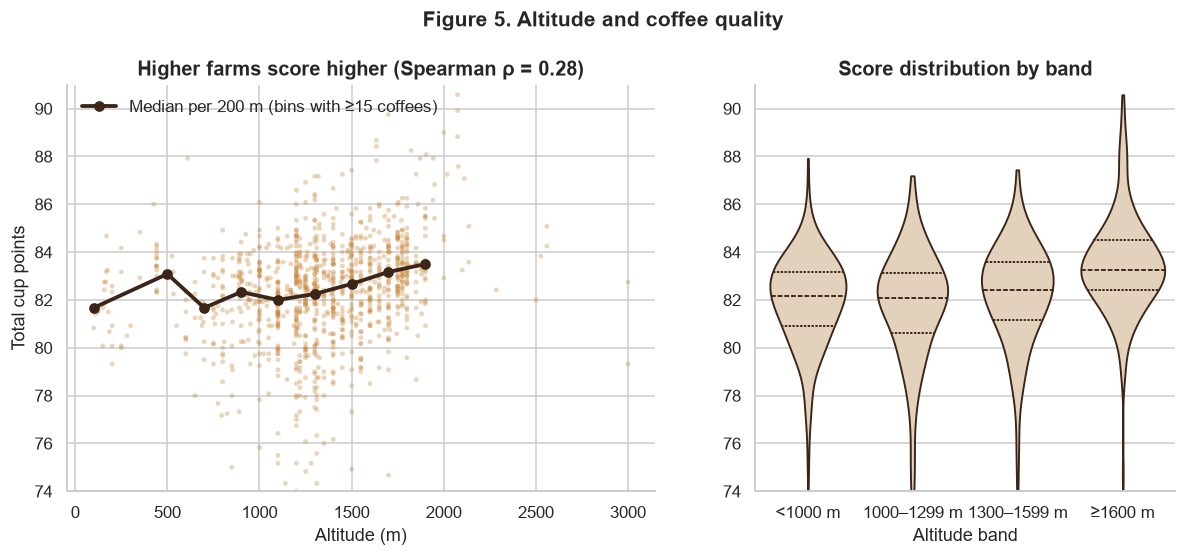

Spearman ρ=0.282, p=4.4e-21  |  Kruskal-Wallis across bands p=2.0e-20


,count,median,mean
alt_band,,,
<1000 m,206,82.17,81.74
1000–1299 m,303,82.08,81.64
1300–1599 m,311,82.42,82.03
≥1600 m,253,83.25,83.44


In [8]:
alt = df.dropna(subset=["altitude_m"])
rho = stats.spearmanr(alt["altitude_m"], alt["total_cup_points"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
ax.scatter(alt["altitude_m"], alt["total_cup_points"], s=10, alpha=0.35, color=CARAMEL, edgecolor="none")
binned = (alt.groupby(pd.cut(alt["altitude_m"], np.arange(0, 3100, 200)), observed=True)["total_cup_points"]
             .agg(["median", "count"]).query("count >= 15"))  # skip bins too thin to trust
ax.plot([b.mid for b in binned.index], binned["median"], color=ESPRESSO, lw=2.5, marker="o",
        label="Median per 200 m (bins with ≥15 coffees)")
ax.set(ylim=(74, 91), xlabel="Altitude (m)", ylabel="Total cup points",
       title=f"Higher farms score higher (Spearman ρ = {rho.statistic:.2f})")
ax.legend(frameon=False)

ax = axes[1]
order = ["<1000 m", "1000–1299 m", "1300–1599 m", "≥1600 m"]
sns.violinplot(data=alt, x="alt_band", y="total_cup_points", order=order, color=CREMA,
               inner="quartile", linecolor=ESPRESSO, cut=0, ax=ax)
ax.set(ylim=(74, 91), xlabel="Altitude band", ylabel="", title="Score distribution by band")
fig.suptitle("Figure 5. Altitude and coffee quality", fontweight="bold", fontsize=14, y=1.02)
fig.savefig(FIG / "fig5_altitude.png"); plt.show()

bands = alt.groupby("alt_band", observed=True)["total_cup_points"].agg(["count", "median", "mean"]).round(2)
kw_alt = stats.kruskal(*[g["total_cup_points"] for _, g in alt.groupby("alt_band", observed=True)])
print(f"Spearman ρ={rho.statistic:.3f}, p={rho.pvalue:.1e}  |  Kruskal-Wallis across bands p={kw_alt.pvalue:.1e}")
display(bands)
results["altitude"] = {"rho": round(rho.statistic, 3), "p": float(rho.pvalue),
                       "band_median": bands["median"].to_dict(), "band_n": bands["count"].to_dict()}

**Finding.** Altitude has a clear, significant positive relationship with score. Below about 1,300 m scores are flat;
above it they climb steadily. Coffees grown at or above 1,600 m average about 1.7 points more than those below 1,000 m
(median gap ≈1.1). There are too few samples above roughly 2,000 m to say whether the trend continues.

## 8. Q5: Which countries score highest?
v1 counted high-altitude samples per country, which shows how many coffees each country *submitted*, not how good they
are. Here we compare average scores for countries with at least 20 reviews.

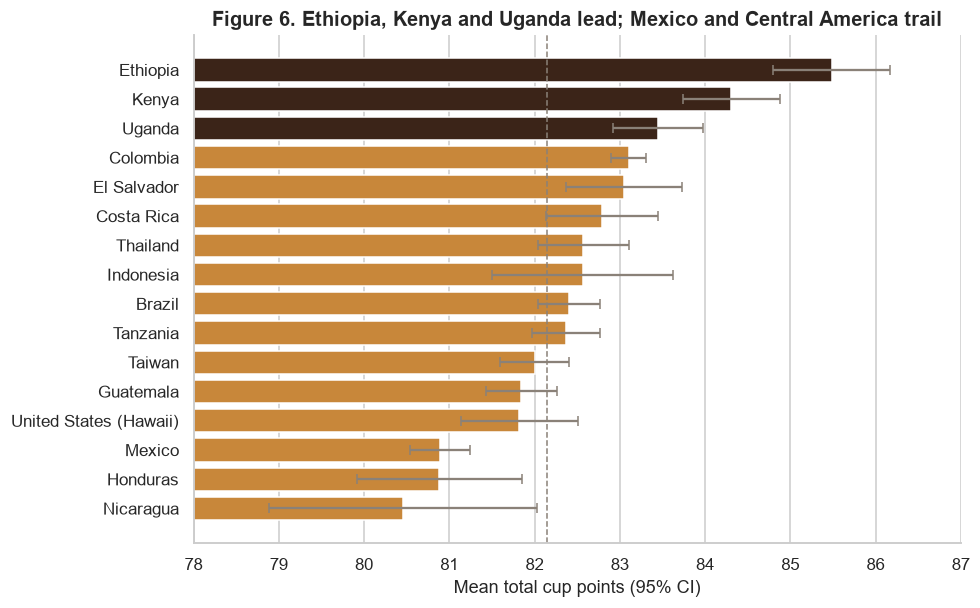

Kruskal-Wallis across countries p=1.0e-45


,mean,sem,n
country,,,
Ethiopia,85.48,0.35,44
Kenya,84.31,0.29,25
Uganda,83.45,0.27,36
Colombia,83.11,0.10,183
El Salvador,83.05,0.35,21
Costa Rica,82.79,0.33,51
Thailand,82.57,0.27,32
Indonesia,82.57,0.54,20
Brazil,82.41,0.19,132


In [9]:
ctry = (df[~df["country"].isin(["Other", "Unknown"])]
          .groupby("country")["total_cup_points"].agg(mean="mean", sem="sem", n="count")
          .sort_values("mean"))
fig, ax = plt.subplots(figsize=(9, 6))
colors = [ESPRESSO if i >= len(ctry) - 3 else CARAMEL for i in range(len(ctry))]
ax.barh(ctry.index, ctry["mean"], xerr=1.96 * ctry["sem"], color=colors, ecolor=GREY, capsize=3)
ax.axvline(df["total_cup_points"].mean(), color=GREY, ls="--", lw=1)
ax.set(xlim=(78, 87), xlabel="Mean total cup points (95% CI)",
       title="Figure 6. Ethiopia, Kenya and Uganda lead; Mexico and Central America trail")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "fig6_country.png"); plt.show()

kw_c = stats.kruskal(*[g["total_cup_points"] for _, g in df[~df["country"].isin(["Other", "Unknown"])].groupby("country")])
print(f"Kruskal-Wallis across countries p={kw_c.pvalue:.1e}")
display(ctry.sort_values("mean", ascending=False).round(2))
results["country_mean"] = ctry["mean"].sort_values(ascending=False).round(2).to_dict()
results["country_n"] = ctry["n"].to_dict()

**Finding.** Country differences are large: East African coffees (Ethiopia ≈85.5, Kenya ≈84.3) average 4–5 points
above Nicaragua, Honduras and Mexico (≈80.5–81). Colombia is the strongest high-volume origin (183 reviews, ≈83.1).

## 9. Q6: Predicting quality from farm and processing data

**Why not predict total score from the sensory scores?** Total cup points *is* the sum of the 10 sensory scores, so that
model would score R² ≈ 1.0 without telling us anything new. The useful question is whether we can predict quality from
information known **before anyone tastes the coffee**: where it was grown, how it was processed, its variety, and the
green-bean inspection.

| Feature | Type |
|---|---|
| altitude_m, moisture, category_one_defects, category_two_defects, quakers, grading_year | numeric |
| country, processing, variety_g, species, color_g | categorical (one-hot encoded) |

Missing numeric values are filled with the median (plus a "was missing" flag); missing categories become "Unknown".
We compare three models with 5-fold cross-validation:
- **Baseline**: always predicts the average score. Any useful model must beat it.
- **Linear regression**: interpretable; each coefficient is a "points per unit" effect.
- **Random Forest**: captures non-linear effects, such as altitude benefits leveling off.

In [10]:
NUM = ["altitude_m", "moisture", "category_one_defects", "category_two_defects", "quakers", "grading_year"]
CAT = ["country", "processing", "variety_g", "species", "color_g"]
X, y = df[NUM + CAT].astype({c: float for c in NUM}), df["total_cup_points"]

pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
])
models = {
    "Baseline (average)": DummyRegressor(),
    "Linear regression": make_pipeline(pre, LinearRegression()),
    "Random Forest": make_pipeline(pre, RandomForestRegressor(
        n_estimators=500, min_samples_leaf=5, max_features=0.5, random_state=42, n_jobs=-1)),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    r = cross_validate(model, X, y, cv=cv, scoring=["r2", "neg_mean_absolute_error"])
    rows.append({"model": name, "R2_mean": r["test_r2"].mean(), "R2_std": r["test_r2"].std(),
                 "MAE_mean": -r["test_neg_mean_absolute_error"].mean()})
cv_table = pd.DataFrame(rows).set_index("model")
display(cv_table.round(3))
results["cv"] = cv_table.round(3).to_dict(orient="index")

,R2_mean,R2_std,MAE_mean
model,,,
Baseline (average),-0.003,0.001,1.829
Linear regression,0.195,0.019,1.653
Random Forest,0.259,0.023,1.575


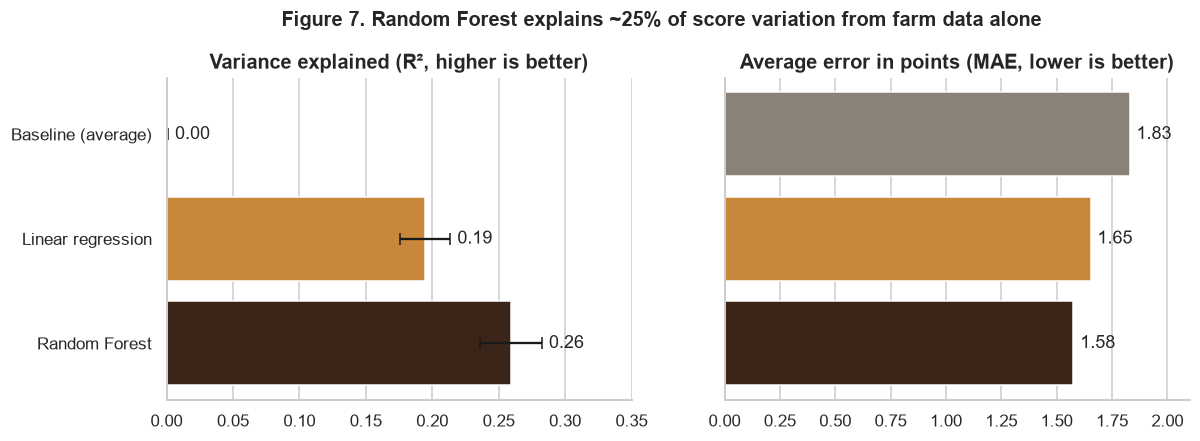

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
c = [GREY, CARAMEL, ESPRESSO]
axes[0].barh(cv_table.index, cv_table["R2_mean"].clip(lower=0), xerr=cv_table["R2_std"], color=c, capsize=4)
axes[0].set(title="Variance explained (R², higher is better)", xlim=(0, 0.35))
axes[1].barh(cv_table.index, cv_table["MAE_mean"], color=c)
axes[1].set(title="Average error in points (MAE, lower is better)", xlim=(0, 2.1))
for ax, col, err in [(axes[0], "R2_mean", cv_table["R2_std"]), (axes[1], "MAE_mean", 0 * cv_table["R2_std"])]:
    for i, (v, e) in enumerate(zip(cv_table[col].clip(lower=0), err)):
        ax.text(v + e + 0.015 * ax.get_xlim()[1], i, f"{v:.2f}", va="center")
    ax.grid(axis="y", visible=False); ax.invert_yaxis()
axes[1].set_yticklabels([])
fig.suptitle("Figure 7. Random Forest explains ~25% of score variation from farm data alone",
             fontweight="bold", fontsize=13, y=1.04)
fig.savefig(FIG / "fig7_model_comparison.png"); plt.show()

### Which factors carry the most weight?
We fit the Random Forest on 80% of the data and measure **permutation importance** on the held-out 20%: shuffle one
feature at a time and see how much accuracy drops. Unlike the Random Forest's built-in importance, this is measured on
unseen data and isn't biased toward features with many categories.

Held-out test: R²=0.222, MAE=1.62 points


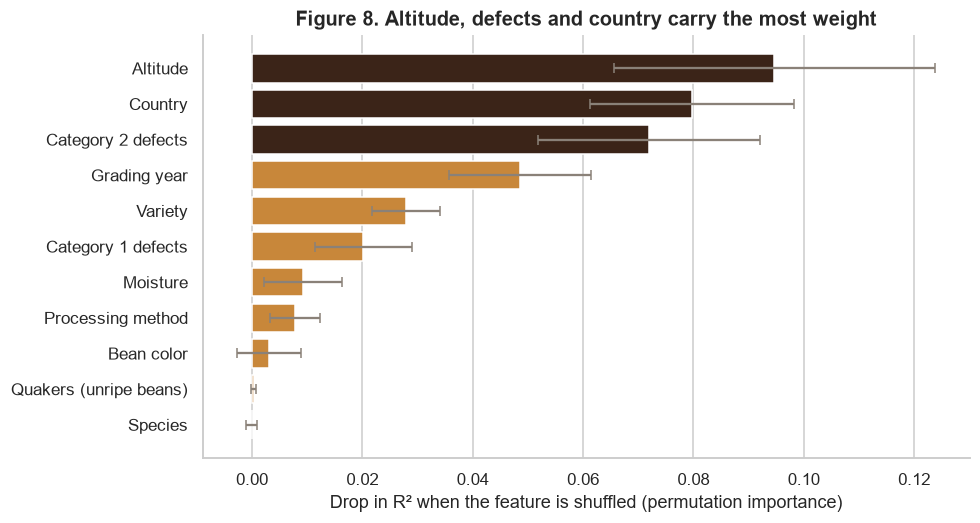

In [12]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
rf = models["Random Forest"].fit(X_tr, y_tr)
pred = rf.predict(X_te)
print(f"Held-out test: R²={r2_score(y_te, pred):.3f}, MAE={mean_absolute_error(y_te, pred):.2f} points")
results["test"] = {"r2": round(r2_score(y_te, pred), 3), "mae": round(mean_absolute_error(y_te, pred), 2)}

pi = permutation_importance(rf, X_te, y_te, n_repeats=30, random_state=42, scoring="r2")
imp = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=X.columns)
imp = imp.sort_values("importance")
labels = {"altitude_m": "Altitude", "category_two_defects": "Category 2 defects", "country": "Country",
          "grading_year": "Grading year", "category_one_defects": "Category 1 defects", "variety_g": "Variety",
          "moisture": "Moisture", "processing": "Processing method", "color_g": "Bean color",
          "quakers": "Quakers (unripe beans)", "species": "Species"}

fig, ax = plt.subplots(figsize=(9, 5))
colors = [ESPRESSO if v >= imp["importance"].nlargest(3).min() else CARAMEL for v in imp["importance"]]
ax.barh(imp.index.map(labels), imp["importance"], xerr=imp["std"], color=colors, ecolor=GREY, capsize=3)
ax.set(title="Figure 8. Altitude, defects and country carry the most weight",
       xlabel="Drop in R² when the feature is shuffled (permutation importance)")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "fig8_feature_importance.png"); plt.show()
results["importance"] = imp["importance"].sort_values(ascending=False).rename(labels).round(4).to_dict()

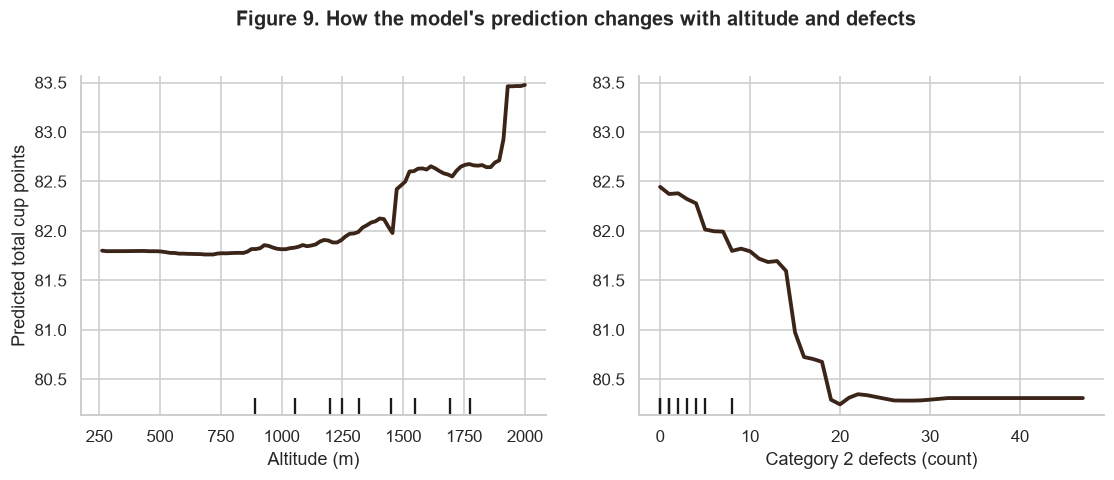

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Partial dependence can't build a grid over missing values, so use rows with a recorded altitude
PartialDependenceDisplay.from_estimator(rf, X_tr.dropna(subset=["altitude_m"]), ["altitude_m", "category_two_defects"],
                                        ax=axes, line_kw={"color": ESPRESSO, "lw": 2.5}, percentiles=(0.02, 0.98))
axes[0].set(xlabel="Altitude (m)", ylabel="Predicted total cup points")
axes[1].set(xlabel="Category 2 defects (count)", ylabel="")
fig.suptitle("Figure 9. How the model's prediction changes with altitude and defects",
             fontweight="bold", fontsize=13, y=1.03)
fig.savefig(FIG / "fig9_partial_dependence.png"); plt.show()

### Linear regression: effect sizes in plain units
The Random Forest ranks the factors; a regression puts them in points. The model uses the same features, with altitude
in units of 100 m. Washed / Wet is the baseline processing method, and Colombia is the baseline country (the largest
high-quality origin).

In [14]:
reg = df.assign(alt_100m=df["altitude_m"] / 100).dropna(subset=["alt_100m"])
ols = smf.ols("total_cup_points ~ alt_100m + category_one_defects + category_two_defects + moisture_f"
              " + C(processing, Treatment('Washed / Wet')) + C(country, Treatment('Colombia')) + C(species)",
              data=reg.assign(moisture_f=reg["moisture"].fillna(reg["moisture"].median()))).fit()
print(f"n={int(ols.nobs)}, R²={ols.rsquared:.3f}, adj. R²={ols.rsquared_adj:.3f}")
key = ols.summary2().tables[1].loc[["alt_100m", "category_one_defects", "category_two_defects"],
                                    ["Coef.", "Std.Err.", "P>|t|"]]
display(key.round(4))
results["ols"] = {k: {"coef": round(v["Coef."], 3), "p": float(v["P>|t|"])} for k, v in key.iterrows()}
results["ols_r2"] = round(ols.rsquared, 3)

n=1073, R²=0.264, adj. R²=0.246


,Coef.,Std.Err.,P>|t|
alt_100m,0.0969,0.0227,0.0000
category_one_defects,-0.0450,0.0408,0.2709
category_two_defects,-0.1076,0.0157,0.0000


**Finding.** From farm data alone, the Random Forest explains about **25%** of the variation in cup score, and its
predictions are off by about 1.6 points on average, versus 1.8 for simply guessing the average. Holding country,
processing and species constant:
- every **100 m of altitude** adds roughly **0.1 point**,
- every **category 2 defect** (broken, insect-damaged or unripe beans) costs about **0.1 point**. Category 1 defects
  are rare (most coffees have none) and their effect is not statistically significant.

The Random Forest's partial dependence (Figure 9) shows the same pattern with more nuance: predicted scores rise with
altitude, and drop sharply once a sample has more than about 15 category 2 defects.

The remaining ~75% of variation comes from things this dataset doesn't capture: roasting, the cupper, the farm's
practices and the individual lot.

## 10. Conclusions
1. **Flavor, aftertaste and overall impression decide the winners.** Uniformity, clean cup and sweetness are near-perfect for almost every coffee.
2. **Scores have become more consistent:** the spread of flavor scores fell about 25% from 2010–12 to 2015–17 (significant).
3. **Processing matters, but only slightly:** a significant ~0.1-point flavor difference that explains about 1% of variation.
4. **Altitude is the strongest single farm-level driver:** a significant positive trend, with ≥1,600 m beating <1,000 m by ~1.7 points on average.
5. **Origin matters:** East African coffees lead by 4–5 points over Mexico and Central America.
6. **A model can weigh these factors:** farm and processing data explain ~25% of quality. Altitude, bean defects and country carry most of the weight.

### Limitations
- Coffees are self-submitted to CQI, so the data is not a random sample of the world's coffee.
- Altitude is self-reported, and 17% of rows are missing it.
- Only 28 robusta samples, so species comparisons are weak.
- Correlation is not causation: high-altitude farms may also differ in investment, variety and care.

### Next steps
- Add roast and price data to explain more of the remaining variation.
- Model the probability of reaching specialty grade (score ≥ 80 or the top 10%) as a classification problem.

In [15]:
Path("results.json").write_text(json.dumps(results, indent=2, default=float), encoding="utf-8")
print("Saved results.json and", len(list(FIG.glob("*.png"))), "figures to", FIG)

Saved results.json and 9 figures to figures
